<a href="https://colab.research.google.com/github/manjunadha12/CSA4703-Deep-Learning/blob/main/Lab/Exp20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== Task 1: Probabilistic PCA (PPCA) Generative Model ===
Model:  x = Wz + mu + epsilon
  - x (d-dim)      : Observed noisy sensor reading
  - z (k-dim)      : Latent factor vector, z ~ N(0, I_k)
  - W (d x k)      : Factor loading matrix mapping latent space to sensor space
  - mu (d-dim)     : Mean sensor reading vector
  - epsilon (d-dim): Isotropic Gaussian sensor noise, epsilon ~ N(0, sigma^2 * I_d)

Marginal distribution: x ~ N(mu, W W^T + sigma^2 * I_d)
Unlike standard PCA, PPCA explicitly models observation noise (sigma^2), enabling
probabilistic denoising, log-likelihood evaluation, and synthetic sample generation.

Sensor Dataset Shape: (500, 8) | True Latent Dim: 3 | True sigma^2: 0.25

=== Task 2 & 3: PPCA Noise Variance Estimation (k = 3) ===
True Noise Variance (sigma^2)      : 0.2500
Estimated Noise Variance (sigma^2) : 0.2416
PPCA Log-Likelihood (avg/sample)   : -11.2015

=== Task 4: Reconstruction MSE vs Component Count ===
 k | Est sigma^2 | PCA MSE (Noisy) | PPCA MSE

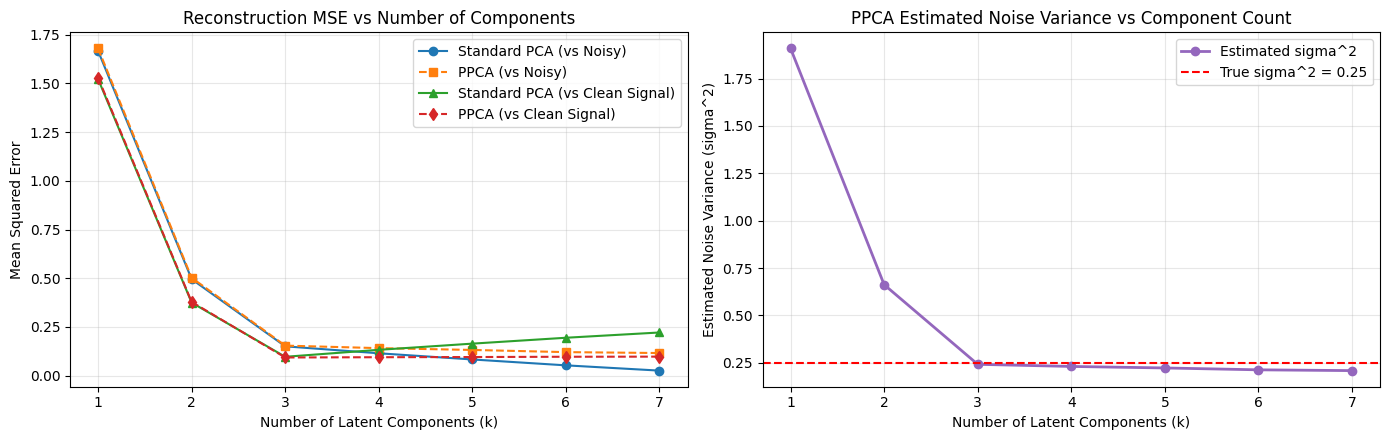


=== Task 5: Real vs Synthetic Sensor Samples (Mean & Std) ===
Temperature | Real:   65.11 +/- 1.93 | Generated:   65.13 +/- 1.92
Vibration   | Real:    2.47 +/- 0.93 | Generated:    2.47 +/- 0.94
Pressure    | Real:  101.07 +/- 1.75 | Generated:  101.07 +/- 1.81
Current     | Real:   12.33 +/- 2.80 | Generated:   12.31 +/- 2.85


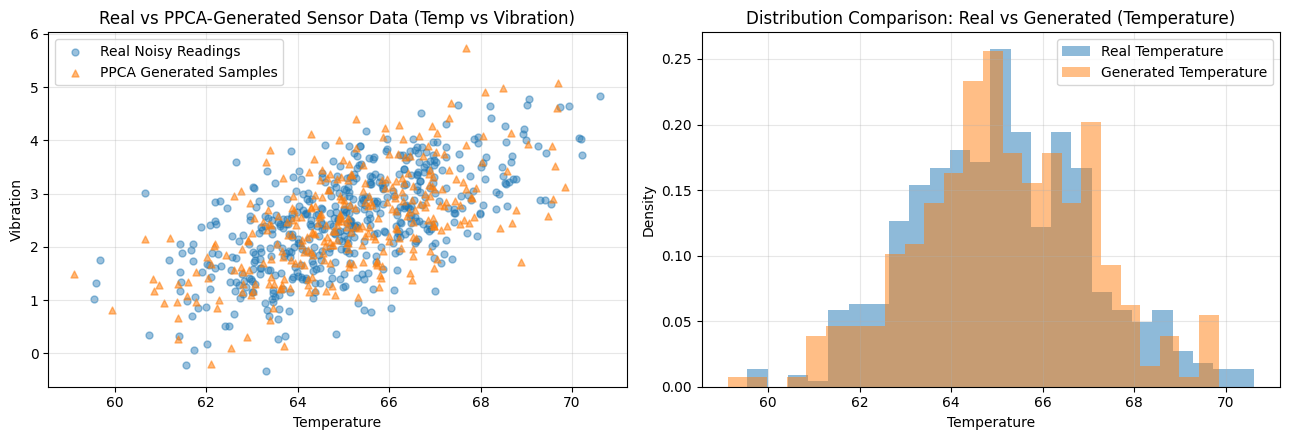

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Reproducibility
np.random.seed(42)

# ==========================================
# Task 1: Explain the PPCA Generative Model
# ==========================================
print("""=== Task 1: Probabilistic PCA (PPCA) Generative Model ===
Model:  x = Wz + mu + epsilon
  - x (d-dim)      : Observed noisy sensor reading
  - z (k-dim)      : Latent factor vector, z ~ N(0, I_k)
  - W (d x k)      : Factor loading matrix mapping latent space to sensor space
  - mu (d-dim)     : Mean sensor reading vector
  - epsilon (d-dim): Isotropic Gaussian sensor noise, epsilon ~ N(0, sigma^2 * I_d)

Marginal distribution: x ~ N(mu, W W^T + sigma^2 * I_d)
Unlike standard PCA, PPCA explicitly models observation noise (sigma^2), enabling
probabilistic denoising, log-likelihood evaluation, and synthetic sample generation.
""")

# ==========================================
# Generate Synthetic Smart-Factory Sensor Readings (8 sensors, 3 latent factors)
# ==========================================
sensor_names = [
    "Temperature", "Vibration", "Pressure", "Current",
    "Voltage", "RPM", "Humidity", "Acoustic"
]
n_samples = 500
n_sensors = len(sensor_names)
true_latent_dim = 3
true_sigma2 = 0.25  # True isotropic noise variance (std = 0.5)

Z_true = np.random.normal(0, 1, (n_samples, true_latent_dim))
W_true = np.random.normal(0, 1.5, (n_sensors, true_latent_dim))
mu_true = np.array([65.0, 2.5, 101.0, 12.0, 230.0, 1500.0, 45.0, 70.0])

X_clean = Z_true @ W_true.T + mu_true
noise = np.random.normal(0, np.sqrt(true_sigma2), (n_samples, n_sensors))
X_noisy = X_clean + noise

print(f"Sensor Dataset Shape: {X_noisy.shape} | True Latent Dim: {true_latent_dim} | True sigma^2: {true_sigma2}\n")

# ==========================================
# Task 2 & 3: Fit PPCA & Estimate Noise Variance (sigma^2)
# ==========================================
def fit_ppca(X, k):
    """Fit PPCA using Scikit-learn PCA MLE noise variance & closed-form W_ML."""
    pca = PCA(n_components=k, svd_solver="full")
    pca.fit(X)
    sigma2_hat = pca.noise_variance_
    # W_ML = U_k * sqrt(Lambda_k - sigma^2 * I)
    eigvals = np.maximum(pca.explained_variance_ - sigma2_hat, 0.0)
    W_ml = pca.components_.T @ np.diag(np.sqrt(eigvals))
    return pca, W_ml, sigma2_hat

def ppca_reconstruct(X, mu, W_ml, sigma2_hat):
    """Reconstruct X using PPCA posterior mean E[z|x]."""
    k = W_ml.shape[1]
    M = W_ml.T @ W_ml + sigma2_hat * np.eye(k)
    Z_post = (X - mu) @ W_ml @ np.linalg.inv(M)
    return Z_post @ W_ml.T + mu

pca_3, W_ml_3, sigma2_est = fit_ppca(X_noisy, k=3)
print("=== Task 2 & 3: PPCA Noise Variance Estimation (k = 3) ===")
print(f"True Noise Variance (sigma^2)      : {true_sigma2:.4f}")
print(f"Estimated Noise Variance (sigma^2) : {sigma2_est:.4f}")
print(f"PPCA Log-Likelihood (avg/sample)   : {pca_3.score(X_noisy):.4f}\n")

# ==========================================
# Task 4: Reconstruct Data & Compare Error vs Component Count
# ==========================================
k_values = list(range(1, n_sensors))
pca_mse_noisy, ppca_mse_noisy = [], []
pca_mse_clean, ppca_mse_clean = [], []
sigma2_by_k = []

for k in k_values:
    pca_k, W_k, s2_k = fit_ppca(X_noisy, k)
    sigma2_by_k.append(s2_k)

    # Standard PCA reconstruction
    X_rec_pca = pca_k.inverse_transform(pca_k.transform(X_noisy))
    # PPCA posterior-mean reconstruction (denoised shrinkage)
    X_rec_ppca = ppca_reconstruct(X_noisy, pca_k.mean_, W_k, s2_k)

    pca_mse_noisy.append(np.mean((X_noisy - X_rec_pca) ** 2))
    ppca_mse_noisy.append(np.mean((X_noisy - X_rec_ppca) ** 2))
    pca_mse_clean.append(np.mean((X_clean - X_rec_pca) ** 2))
    ppca_mse_clean.append(np.mean((X_clean - X_rec_ppca) ** 2))

print("=== Task 4: Reconstruction MSE vs Component Count ===")
print(f"{'k':>2} | {'Est sigma^2':>11} | {'PCA MSE (Noisy)':>15} | {'PPCA MSE (Noisy)':>16} | {'PCA MSE (Clean)':>15} | {'PPCA MSE (Clean)':>16}")
print("-" * 88)
for i, k in enumerate(k_values):
    print(f"{k:2d} | {sigma2_by_k[i]:11.4f} | {pca_mse_noisy[i]:15.4f} | {ppca_mse_noisy[i]:16.4f} | {pca_mse_clean[i]:15.4f} | {ppca_mse_clean[i]:16.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(k_values, pca_mse_noisy, marker="o", label="Standard PCA (vs Noisy)")
axes[0].plot(k_values, ppca_mse_noisy, marker="s", linestyle="--", label="PPCA (vs Noisy)")
axes[0].plot(k_values, pca_mse_clean, marker="^", label="Standard PCA (vs Clean Signal)")
axes[0].plot(k_values, ppca_mse_clean, marker="d", linestyle="--", label="PPCA (vs Clean Signal)")
axes[0].set_title("Reconstruction MSE vs Number of Components")
axes[0].set_xlabel("Number of Latent Components (k)")
axes[0].set_ylabel("Mean Squared Error")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(k_values, sigma2_by_k, marker="o", color="tab:purple", linewidth=2, label="Estimated sigma^2")
axes[1].axhline(true_sigma2, color="red", linestyle="--", label=f"True sigma^2 = {true_sigma2}")
axes[1].set_title("PPCA Estimated Noise Variance vs Component Count")
axes[1].set_xlabel("Number of Latent Components (k)")
axes[1].set_ylabel("Estimated Noise Variance (sigma^2)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ==========================================
# Task 5: Generate New Synthetic Sensor Samples from Fitted PPCA Model
# ==========================================
n_gen = 300
Z_gen = np.random.normal(0, 1, (n_gen, 3))
eps_gen = np.random.normal(0, np.sqrt(sigma2_est), (n_gen, n_sensors))
X_generated = Z_gen @ W_ml_3.T + pca_3.mean_ + eps_gen

print("\n=== Task 5: Real vs Synthetic Sensor Samples (Mean & Std) ===")
for idx, name in enumerate(sensor_names[:4]):
    print(f"{name:11s} | Real: {X_noisy[:, idx].mean():7.2f} +/- {X_noisy[:, idx].std():.2f} | "
          f"Generated: {X_generated[:, idx].mean():7.2f} +/- {X_generated[:, idx].std():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# 2D scatter of Temperature vs Vibration
axes[0].scatter(X_noisy[:, 0], X_noisy[:, 1], alpha=0.45, label="Real Noisy Readings", s=25)
axes[0].scatter(X_generated[:, 0], X_generated[:, 1], alpha=0.55, label="PPCA Generated Samples", s=25, marker="^")
axes[0].set_title("Real vs PPCA-Generated Sensor Data (Temp vs Vibration)")
axes[0].set_xlabel("Temperature")
axes[0].set_ylabel("Vibration")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Distribution comparison for Temperature
axes[1].hist(X_noisy[:, 0], bins=25, alpha=0.5, density=True, label="Real Temperature")
axes[1].hist(X_generated[:, 0], bins=25, alpha=0.5, density=True, label="Generated Temperature")
axes[1].set_title("Distribution Comparison: Real vs Generated (Temperature)")
axes[1].set_xlabel("Temperature")
axes[1].set_ylabel("Density")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
